# IAU – Fáza 2:  Predspracovanie údajov

## Autori
- Sofiia Berehovykh – 50 %
- Viktoriia Bondarets – 50 %

In [12]:
from pathlib import Path
import numpy as np
import pandas as pd

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import (
    StandardScaler,
    MinMaxScaler,
    PowerTransformer,
    QuantileTransformer,
    OneHotEncoder
)

if Path("data").is_dir():
    DATA_DIR = Path("data")
elif Path("../data").is_dir():
    DATA_DIR = Path("../data")
else:
    raise FileNotFoundError("Data folder not found")

units = pd.read_csv(DATA_DIR / "units.csv")
readings = pd.read_csv(DATA_DIR / "readings.csv", sep="\t")

readings_clean = readings.drop_duplicates().copy()
units_clean = units.copy()

readings_clean["idUnit"] = pd.to_numeric(
    readings_clean["idUnit"].astype(str).str.extract(r"^U(\d+)$")[0],
    errors="coerce"
)

units_clean["idUnit"] = pd.to_numeric(
    units_clean["idUnit"],
    errors="coerce"
)

readings_clean["tsCycle"] = pd.to_datetime(
    readings_clean["tsCycle"],
    format="mixed",
    errors="coerce"
)

readings_clean["temperatureOil"] = readings_clean[
    "temperatureOil"
].replace(-999, np.nan)

units_clean["dutyClass"] = units_clean["dutyClass"].apply(
    lambda x: x.strip().lower() if isinstance(x, str) else np.nan
)

data = readings_clean.merge(
    units_clean,
    on="idUnit",
    how="left",
    validate="many_to_one",
    indicator=True,
    suffixes=("", "_unit")
)

print("Merge results:")
display(data["_merge"].value_counts())

data = data.drop(columns=["_merge"])

data["cycle_year"] = data["tsCycle"].dt.year
data["cycle_month"] = data["tsCycle"].dt.month
data["cycle_dayofweek"] = data["tsCycle"].dt.dayofweek
data["cycle_hour"] = data["tsCycle"].dt.hour

data = data.drop(
    columns=["idUnit", "tsCycle", "number_serial", "operatorOwner"],
    errors="ignore"
)

data = data.replace([np.inf, -np.inf], np.nan)
data = data.dropna(subset=["failure"]).copy()
data = data.loc[data["failure"].isin([0, 1])].copy()
data["failure"] = data["failure"].astype(int)

print("Final dataset shape:", data.shape)
print("Duplicate rows:", data.duplicated().sum())
print("Missing values:", data.isna().sum().sum())

display(data.head())

Merge results:


_merge
both          14679
left_only       140
right_only        0
Name: count, dtype: int64

Final dataset shape: (14819, 19)
Duplicate rows: 0
Missing values: 2778


,currentMotor,dp_filter,temperatureOil,pressure_reservoir,pressure_oil,rms_vibration,Flowmeter,discharge_dewpoint,failure,year_commission,idDepot,codeLine,serviceHours,code_model,dutyClass,cycle_year,cycle_month,cycle_dayofweek,cycle_hour
0,4.52714,13.27287,38.37190,8.71234,3.20650,2.98947,26.46027,9.88857,0,2021.0,33.0,L6,11660.4,APU-15,l,2023,1,1,0
1,4.29990,30.68875,62.89222,8.30207,3.50414,5.42665,30.37617,3.50537,0,2021.0,2.0,L5,13438.9,XC-7,light,2023,3,3,0
2,2.67461,20.64984,44.05538,8.53038,3.31134,3.19845,15.69089,0.94667,0,2023.0,67.0,L3,6663.4,APU-20,1,2023,1,0,0
3,4.06722,30.65835,76.27459,8.98351,3.88235,2.13170,24.62591,12.19307,1,2017.0,12.0,L4,24578.2,APU-15,1,2023,11,0,0
4,7.30514,23.53441,57.95202,8.31182,3.18153,2.50357,21.52352,11.89736,0,2017.0,29.0,L1,26640.5,APU-20,h,2023,12,5,22


In [13]:
X = data.drop(columns=["failure"])
y = data["failure"]

categorical_candidates = [
    "idDepot",
    "codeLine",
    "code_model",
    "dutyClass"
]

for col in categorical_candidates:
    if col in X.columns:
        X[col] = X[col].apply(
            lambda x: str(x) if pd.notna(x) else np.nan
        )

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

numeric_features = X_train.select_dtypes(
    include=["number"]
).columns.tolist()

categorical_features = X_train.select_dtypes(
    exclude=["number"]
).columns.tolist()

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

print("\nNumeric features:")
print(numeric_features)

print("\nCategorical features:")
print(categorical_features)

print("\nTraining target distribution:")
display(y_train.value_counts(normalize=True).sort_index())

print("\nTesting target distribution:")
display(y_test.value_counts(normalize=True).sort_index())

X_train: (11855, 18)
X_test: (2964, 18)
y_train: (11855,)
y_test: (2964,)

Numeric features:
['currentMotor', 'dp_filter', 'temperatureOil', 'pressure_reservoir', 'pressure_oil', 'rms_vibration', 'Flowmeter', 'discharge_dewpoint', 'year_commission', 'serviceHours', 'cycle_year', 'cycle_month', 'cycle_dayofweek', 'cycle_hour']

Categorical features:
['idDepot', 'codeLine', 'code_model', 'dutyClass']

Training target distribution:


failure
0    0.879038
1    0.120962
Name: proportion, dtype: float64


Testing target distribution:


failure
0    0.87888
1    0.12112
Name: proportion, dtype: float64

In [14]:
def create_preprocessor(numeric_transformer):
    numeric_pipeline = Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("transformer", numeric_transformer)
    ])

    categorical_pipeline = Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", OneHotEncoder(
            handle_unknown="ignore",
            sparse_output=False
        ))
    ])

    return ColumnTransformer([
        ("numeric", numeric_pipeline, numeric_features),
        ("categorical", categorical_pipeline, categorical_features)
    ], remainder="drop")


def transform_datasets(numeric_transformer):
    preprocessor = create_preprocessor(numeric_transformer)

    train_array = preprocessor.fit_transform(X_train)
    test_array = preprocessor.transform(X_test)

    feature_names = preprocessor.get_feature_names_out()

    train_result = pd.DataFrame(
        train_array,
        columns=feature_names,
        index=X_train.index
    )

    test_result = pd.DataFrame(
        test_array,
        columns=feature_names,
        index=X_test.index
    )

    return preprocessor, train_result, test_result

In [15]:
scaling_methods = {
    "StandardScaler": StandardScaler(),
    "MinMaxScaler": MinMaxScaler()
}

scaling_results = {}

for name, scaler in scaling_methods.items():
    preprocessor, train_result, test_result = transform_datasets(scaler)

    scaling_results[name] = {
        "preprocessor": preprocessor,
        "X_train": train_result,
        "X_test": test_result
    }

    print(f"\n{name}")
    print("Train shape:", train_result.shape)
    print("Test shape:", test_result.shape)
    print("Train missing values:", train_result.isna().sum().sum())
    print("Test missing values:", test_result.isna().sum().sum())
    print("All train features numeric:", train_result.select_dtypes(
        exclude=["number"]
    ).empty)

    display(train_result.head())


StandardScaler
Train shape: (11855, 154)
Test shape: (2964, 154)
Train missing values: 0
Test missing values: 0
All train features numeric: True


,numeric__currentMotor,numeric__dp_filter,numeric__temperatureOil,numeric__pressure_reservoir,numeric__pressure_oil,numeric__rms_vibration,numeric__Flowmeter,numeric__discharge_dewpoint,numeric__year_commission,numeric__serviceHours,...,categorical__dutyClass_1,categorical__dutyClass_2,categorical__dutyClass_3,categorical__dutyClass_h,categorical__dutyClass_heavy,categorical__dutyClass_l,categorical__dutyClass_light,categorical__dutyClass_med,categorical__dutyClass_n,categorical__dutyClass_normal
14762,-0.464763,-0.087761,0.916693,-2.128255,-1.147802,-0.133832,0.758549,-0.302847,0.243700,-0.338721,...,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
11718,-0.659646,-0.285536,0.754337,-0.432716,-0.457888,-0.938951,-0.387430,0.554513,0.649013,-0.453181,...,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0
4288,-0.215242,-0.241339,0.175098,1.878102,1.794163,1.664415,0.330795,0.805821,0.649013,-0.241173,...,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0
14013,-0.393936,-0.929633,0.393338,-0.188573,-0.279940,0.002574,-0.463789,-1.123072,0.243700,-0.078838,...,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0
3439,0.092208,-0.045761,-2.513271,-1.215740,-0.812226,-0.108791,-0.192135,-1.237069,-0.566925,0.493877,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0



MinMaxScaler
Train shape: (11855, 154)
Test shape: (2964, 154)
Train missing values: 0
Test missing values: 0
All train features numeric: True


,numeric__currentMotor,numeric__dp_filter,numeric__temperatureOil,numeric__pressure_reservoir,numeric__pressure_oil,numeric__rms_vibration,numeric__Flowmeter,numeric__discharge_dewpoint,numeric__year_commission,numeric__serviceHours,...,categorical__dutyClass_1,categorical__dutyClass_2,categorical__dutyClass_3,categorical__dutyClass_h,categorical__dutyClass_heavy,categorical__dutyClass_l,categorical__dutyClass_light,categorical__dutyClass_med,categorical__dutyClass_n,categorical__dutyClass_normal
14762,0.032003,0.152106,0.636261,0.228770,0.342829,0.174213,0.641494,0.425764,0.750000,0.231182,...,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
11718,0.024114,0.131662,0.612023,0.485053,0.430347,0.077760,0.460380,0.537157,0.833333,0.209243,...,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0
4288,0.042104,0.136231,0.525547,0.834335,0.716027,0.389644,0.573890,0.569809,0.833333,0.249880,...,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0
14013,0.034870,0.065081,0.558129,0.521955,0.452920,0.190555,0.448312,0.319195,0.750000,0.280995,...,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0
3439,0.054550,0.156448,0.124195,0.366697,0.385398,0.177213,0.491245,0.304383,0.583333,0.390770,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0


In [16]:
transformer_methods = {
    "PowerTransformer": PowerTransformer(
        method="yeo-johnson",
        standardize=True
    ),
    "QuantileTransformer": QuantileTransformer(
        n_quantiles=min(1000, len(X_train)),
        output_distribution="normal",
        random_state=42
    )
}

transformer_results = {}

for name, transformer in transformer_methods.items():
    preprocessor, train_result, test_result = transform_datasets(transformer)

    transformer_results[name] = {
        "preprocessor": preprocessor,
        "X_train": train_result,
        "X_test": test_result
    }

    print(f"\n{name}")
    print("Train shape:", train_result.shape)
    print("Test shape:", test_result.shape)
    print("Train missing values:", train_result.isna().sum().sum())
    print("Test missing values:", test_result.isna().sum().sum())
    print("All train features numeric:", train_result.select_dtypes(
        exclude=["number"]
    ).empty)

    display(train_result.head())


PowerTransformer
Train shape: (11855, 154)
Test shape: (2964, 154)
Train missing values: 0
Test missing values: 0
All train features numeric: True


,numeric__currentMotor,numeric__dp_filter,numeric__temperatureOil,numeric__pressure_reservoir,numeric__pressure_oil,numeric__rms_vibration,numeric__Flowmeter,numeric__discharge_dewpoint,numeric__year_commission,numeric__serviceHours,...,categorical__dutyClass_1,categorical__dutyClass_2,categorical__dutyClass_3,categorical__dutyClass_h,categorical__dutyClass_heavy,categorical__dutyClass_l,categorical__dutyClass_light,categorical__dutyClass_med,categorical__dutyClass_n,categorical__dutyClass_normal
14762,-0.853741,0.177773,0.916656,-2.127809,-1.146692,0.101379,0.756577,-0.299321,0.232057,-0.133245,...,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
11718,-1.475438,-0.070771,0.753536,-0.432819,-0.462492,-1.150552,-0.392901,0.556139,0.654604,-0.289160,...,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0
4288,-0.221573,-0.012352,0.172578,1.878412,1.806330,1.529692,0.325738,0.806144,0.654604,-0.009940,...,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0
14013,-0.658655,-1.197001,0.391276,-0.188693,-0.285127,0.256315,-0.468934,-1.122531,0.232057,0.178811,...,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0
3439,0.392893,0.226589,-2.496808,-1.215686,-0.814595,0.130719,-0.198108,-1.237441,-0.593994,0.725346,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0



QuantileTransformer
Train shape: (11855, 154)
Test shape: (2964, 154)
Train missing values: 0
Test missing values: 0
All train features numeric: True


,numeric__currentMotor,numeric__dp_filter,numeric__temperatureOil,numeric__pressure_reservoir,numeric__pressure_oil,numeric__rms_vibration,numeric__Flowmeter,numeric__discharge_dewpoint,numeric__year_commission,numeric__serviceHours,...,categorical__dutyClass_1,categorical__dutyClass_2,categorical__dutyClass_3,categorical__dutyClass_h,categorical__dutyClass_heavy,categorical__dutyClass_l,categorical__dutyClass_light,categorical__dutyClass_med,categorical__dutyClass_n,categorical__dutyClass_normal
14762,-0.830486,0.222030,0.925800,-2.147483,-1.140277,0.137126,0.742215,-0.291235,0.012546,-0.183383,...,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
11718,-1.409363,-0.108393,0.751736,-0.430212,-0.468306,-1.138275,-0.385944,0.564956,0.586473,-0.349483,...,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0
4288,-0.269743,0.000000,0.174701,1.866372,1.800062,1.487275,0.323213,0.819585,0.586473,0.002509,...,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0
14013,-0.646390,-1.175570,0.397446,-0.186622,-0.288988,0.279888,-0.466495,-1.119921,0.012546,0.273241,...,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0
3439,0.275704,0.262089,-2.466423,-1.209260,-0.805281,0.157609,-0.196576,-1.220216,-0.771450,0.754668,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0


In [17]:
OUTPUT_DIR = Path("faza2_data")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

all_results = {
    **scaling_results,
    **transformer_results
}

for name, result in all_results.items():
    train_output = result["X_train"].copy()
    train_output["failure"] = y_train.loc[train_output.index]

    test_output = result["X_test"].copy()
    test_output["failure"] = y_test.loc[test_output.index]

    filename = name.lower()

    train_output.to_csv(
        OUTPUT_DIR / f"{filename}_train.csv",
        index=False
    )

    test_output.to_csv(
        OUTPUT_DIR / f"{filename}_test.csv",
        index=False
    )

    print(
        f"{name}: train={train_output.shape}, "
        f"test={test_output.shape}"
    )

print("\nSaved files:")
for path in sorted(OUTPUT_DIR.glob("*.csv")):
    print(path)

StandardScaler: train=(11855, 155), test=(2964, 155)
MinMaxScaler: train=(11855, 155), test=(2964, 155)
PowerTransformer: train=(11855, 155), test=(2964, 155)
QuantileTransformer: train=(11855, 155), test=(2964, 155)

Saved files:
faza2_data\minmaxscaler_test.csv
faza2_data\minmaxscaler_train.csv
faza2_data\powertransformer_test.csv
faza2_data\powertransformer_train.csv
faza2_data\quantiletransformer_test.csv
faza2_data\quantiletransformer_train.csv
faza2_data\standardscaler_test.csv
faza2_data\standardscaler_train.csv


## 2.2

In [19]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.feature_selection import f_classif, mutual_info_classif
from sklearn.ensemble import RandomForestClassifier

DATA_DIR = Path("faza2_data")
train = pd.read_csv(DATA_DIR / "standardscaler_train.csv")

X = train.drop(columns=["failure"])
y = train["failure"].astype(int)

constant_features = X.columns[X.nunique(dropna=False) <= 1].tolist()
X = X.drop(columns=constant_features)

print("Počet trénovacích pozorovaní:", len(X))
print("Počet atribútov po odstránení konštantných atribútov:", X.shape[1])
print("Odstránené konštantné atribúty:", constant_features)
print("Rozdelenie cieľovej premennej:")
print(y.value_counts())

Počet trénovacích pozorovaní: 11855
Počet atribútov po odstránení konštantných atribútov: 153
Odstránené konštantné atribúty: ['numeric__cycle_year']
Rozdelenie cieľovej premennej:
failure
0    10421
1     1434
Name: count, dtype: int64


In [20]:
f_scores, f_pvalues = f_classif(X, y)

anova_results = pd.DataFrame({
    "feature": X.columns,
    "anova_f": f_scores,
    "anova_pvalue": f_pvalues
}).sort_values("anova_f", ascending=False)

display(anova_results.head(20))

,feature,anova_f,anova_pvalue
8,numeric__year_commission,219.755677,2.822440e-49
9,numeric__serviceHours,215.402507,2.415971e-48
1,numeric__dp_filter,94.894537,2.435241e-22
3,numeric__pressure_reservoir,80.928248,2.694786e-19
148,categorical__dutyClass_l,75.690226,3.754623e-18
7,numeric__discharge_dewpoint,64.866317,8.780367e-16
4,numeric__pressure_oil,59.704044,1.191250e-14
146,categorical__dutyClass_h,51.885588,6.239247e-13
149,categorical__dutyClass_light,43.046213,5.568739e-11
147,categorical__dutyClass_heavy,39.817663,2.887505e-10


In [21]:
mi_scores = mutual_info_classif(
    X,
    y,
    random_state=42,
    n_neighbors=3
)

mi_results = pd.DataFrame({
    "feature": X.columns,
    "mutual_info": mi_scores
}).sort_values("mutual_info", ascending=False)

display(mi_results.head(20))

,feature,mutual_info
1,numeric__dp_filter,0.035267
5,numeric__rms_vibration,0.025075
9,numeric__serviceHours,0.016134
141,categorical__code_model_APU-20,0.007877
148,categorical__dutyClass_l,0.006733
8,numeric__year_commission,0.006697
0,numeric__currentMotor,0.006319
58,categorical__idDepot_31.0,0.006053
143,categorical__dutyClass_1,0.005782
98,categorical__idDepot_68.0,0.005247


In [22]:
rf = RandomForestClassifier(
    n_estimators=250,
    random_state=42,
    class_weight="balanced_subsample",
    min_samples_leaf=2,
    n_jobs=-1
)

rf.fit(X, y)

rf_results = pd.DataFrame({
    "feature": X.columns,
    "rf_importance": rf.feature_importances_
}).sort_values("rf_importance", ascending=False)

display(rf_results.head(20))

,feature,rf_importance
1,numeric__dp_filter,0.110849
5,numeric__rms_vibration,0.086358
0,numeric__currentMotor,0.072881
9,numeric__serviceHours,0.072686
7,numeric__discharge_dewpoint,0.064898
3,numeric__pressure_reservoir,0.063684
4,numeric__pressure_oil,0.060069
2,numeric__temperatureOil,0.058876
6,numeric__Flowmeter,0.055523
8,numeric__year_commission,0.040796


In [23]:
ranking = pd.DataFrame({"feature": X.columns})

ranking["anova_f"] = f_scores
ranking["mutual_info"] = mi_scores
ranking["rf_importance"] = rf.feature_importances_

ranking["anova_rank"] = ranking["anova_f"].rank(
    ascending=False, method="min"
).astype(int)

ranking["mi_rank"] = ranking["mutual_info"].rank(
    ascending=False, method="min"
).astype(int)

ranking["rf_rank"] = ranking["rf_importance"].rank(
    ascending=False, method="min"
).astype(int)

ranking["average_rank"] = ranking[
    ["anova_rank", "mi_rank", "rf_rank"]
].mean(axis=1)

ranking = ranking.sort_values("average_rank")

display(ranking.head(20).reset_index(drop=True))

,feature,anova_f,mutual_info,rf_importance,anova_rank,mi_rank,rf_rank,average_rank
0,numeric__dp_filter,94.894537,0.035267,0.110849,3,1,1,1.666667
1,numeric__serviceHours,215.402507,0.016134,0.072686,2,3,4,3.000000
2,numeric__rms_vibration,24.841014,0.025075,0.086358,12,2,2,5.333333
3,numeric__year_commission,219.755677,0.006697,0.040796,1,6,10,5.666667
4,categorical__dutyClass_l,75.690226,0.006733,0.009575,5,5,14,8.000000
5,numeric__pressure_reservoir,80.928248,0.003779,0.063684,4,15,6,8.333333
6,numeric__discharge_dewpoint,64.866317,0.003102,0.064898,6,21,5,10.666667
7,numeric__pressure_oil,59.704044,0.003156,0.060069,7,19,7,11.000000
8,numeric__currentMotor,7.463883,0.006319,0.072881,24,7,3,11.333333
9,categorical__dutyClass_1,38.953357,0.005782,0.008851,11,9,16,12.000000


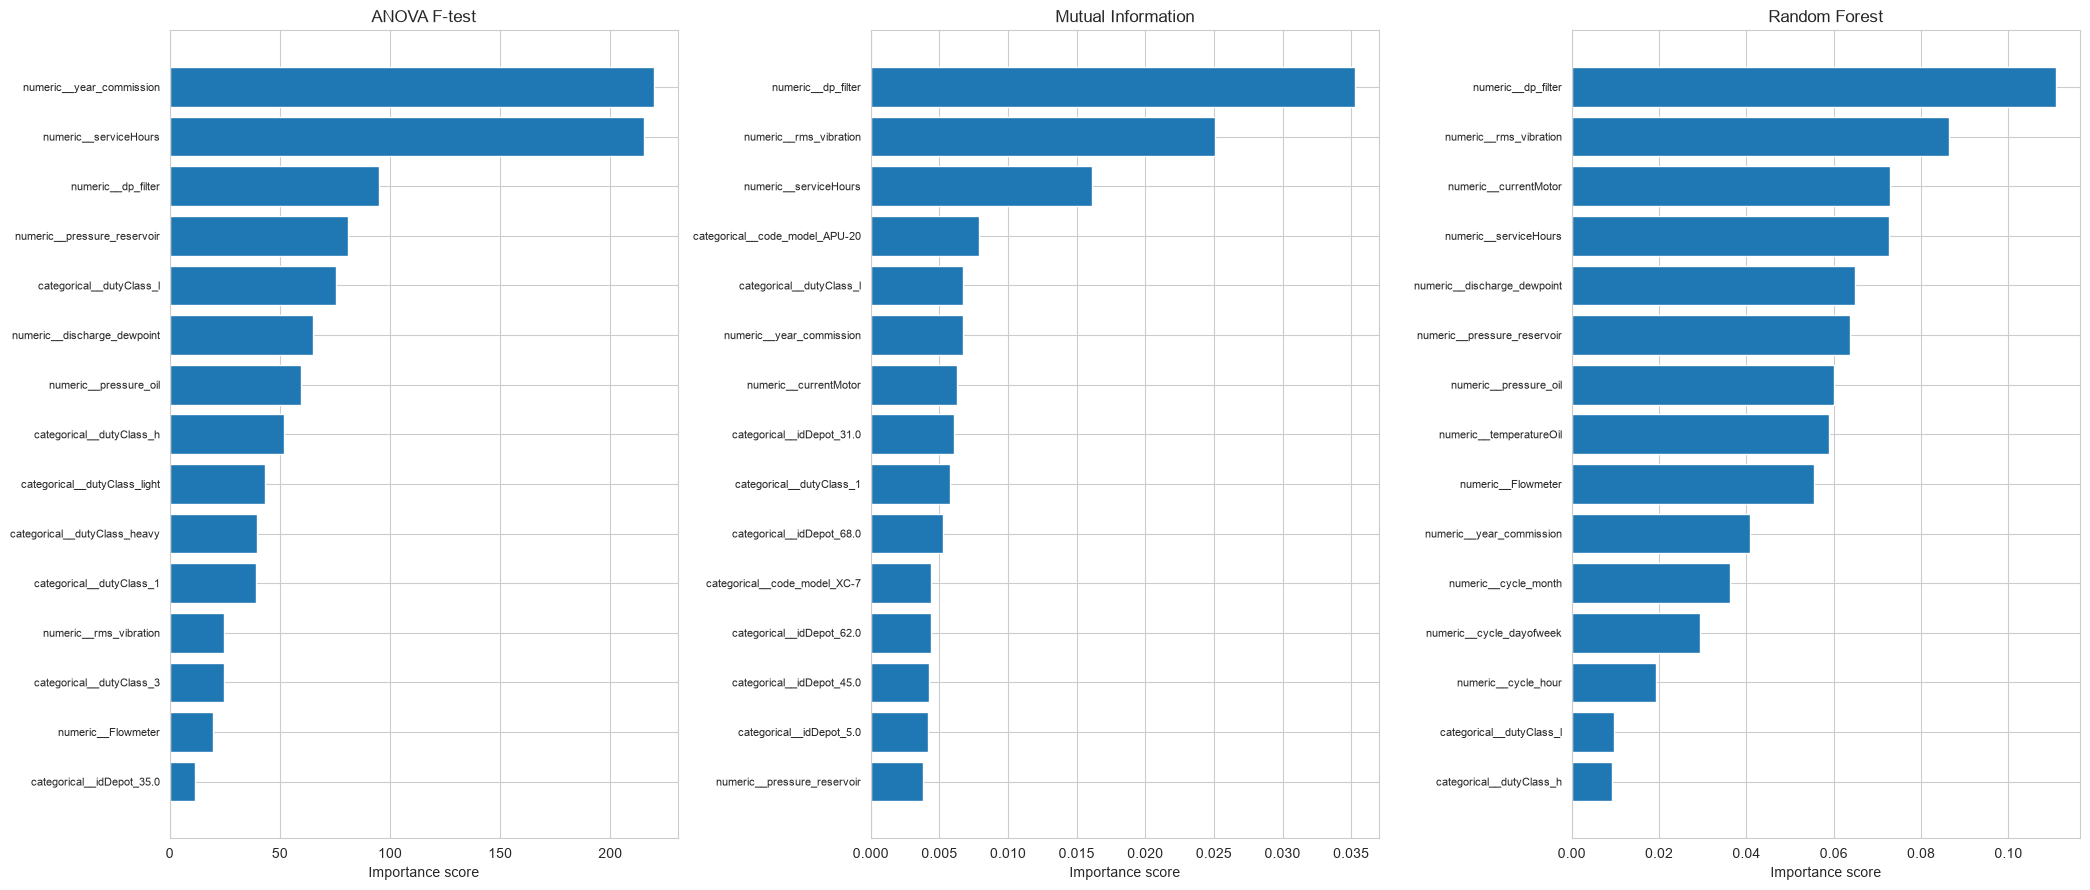

In [24]:
methods = [
    ("anova_f", "ANOVA F-test"),
    ("mutual_info", "Mutual Information"),
    ("rf_importance", "Random Forest")
]

fig, axes = plt.subplots(1, 3, figsize=(21, 9))

for ax, (column, title) in zip(axes, methods):
    top = ranking.sort_values(column, ascending=False).head(15)
    top = top.sort_values(column, ascending=True)

    ax.barh(top["feature"], top[column])
    ax.set_title(title)
    ax.set_xlabel("Importance score")
    ax.tick_params(axis="y", labelsize=8)

plt.tight_layout()
plt.show()

## 2.3 Replikovateľnosť predspracovania

Cieľom tejto časti je vytvoriť opakovateľný proces predspracovania údajov pomocou nástrojov `sklearn.pipeline` a `ColumnTransformer`.

Predspracovanie sa najskôr naučí na trénovacej množine. Následne sa rovnaké transformácie aplikujú na testovaciu množinu bez opätovného učenia transformačných krokov. Tým sa zabezpečí konzistentné spracovanie oboch množín a predíde sa úniku informácií z testovacích dát.

In [26]:
from pathlib import Path

import numpy as np
import pandas as pd

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import (
    StandardScaler,
    MinMaxScaler,
    PowerTransformer,
    QuantileTransformer,
    OneHotEncoder
)

numeric_features = X_train.select_dtypes(include=["number"]).columns.tolist()
categorical_features = X_train.select_dtypes(exclude=["number"]).columns.tolist()

def create_preprocessing_pipeline(numeric_transformer):
    numeric_pipeline = Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", numeric_transformer)
    ])

    categorical_pipeline = Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", OneHotEncoder(
            handle_unknown="ignore",
            sparse_output=False
        ))
    ])

    preprocessor = ColumnTransformer([
        ("numeric", numeric_pipeline, numeric_features),
        ("categorical", categorical_pipeline, categorical_features)
    ])

    return Pipeline([
        ("preprocessing", preprocessor)
    ])

In [27]:
transformers = {
    "standardscaler": StandardScaler(),
    "minmaxscaler": MinMaxScaler(),
    "powertransformer": PowerTransformer(
        method="yeo-johnson",
        standardize=True
    ),
    "quantiletransformer": QuantileTransformer(
        n_quantiles=min(1000, len(X_train)),
        output_distribution="normal",
        random_state=42
    )
}

OUTPUT_DIR = Path("faza2_data")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

preprocessing_pipelines = {}
preprocessed_data = {}

for name, transformer in transformers.items():
    pipeline = create_preprocessing_pipeline(transformer)

    X_train_transformed = pipeline.fit_transform(X_train)
    X_test_transformed = pipeline.transform(X_test)

    feature_names = pipeline.get_feature_names_out()

    train_output = pd.DataFrame(
        X_train_transformed,
        columns=feature_names,
        index=X_train.index
    )
    train_output["failure"] = y_train.to_numpy()

    test_output = pd.DataFrame(
        X_test_transformed,
        columns=feature_names,
        index=X_test.index
    )
    test_output["failure"] = y_test.to_numpy()

    train_output.to_csv(
        OUTPUT_DIR / f"{name}_train.csv",
        index=False
    )
    test_output.to_csv(
        OUTPUT_DIR / f"{name}_test.csv",
        index=False
    )

    preprocessing_pipelines[name] = pipeline
    preprocessed_data[name] = {
        "train": train_output,
        "test": test_output
    }

    print(
        f"{name}: train={train_output.shape}, "
        f"test={test_output.shape}"
    )

standardscaler: train=(11855, 155), test=(2964, 155)
minmaxscaler: train=(11855, 155), test=(2964, 155)
powertransformer: train=(11855, 155), test=(2964, 155)
quantiletransformer: train=(11855, 155), test=(2964, 155)


In [28]:
validation_results = []

for name, datasets in preprocessed_data.items():
    train_output = datasets["train"]
    test_output = datasets["test"]

    train_features = train_output.drop(columns=["failure"])
    test_features = test_output.drop(columns=["failure"])

    validation_results.append({
        "transformer": name,
        "train_rows": len(train_output),
        "test_rows": len(test_output),
        "train_features": train_features.shape[1],
        "test_features": test_features.shape[1],
        "same_features": list(train_features.columns) == list(test_features.columns),
        "train_missing": int(train_features.isna().sum().sum()),
        "test_missing": int(test_features.isna().sum().sum()),
        "target_preserved": (
            train_output["failure"].notna().all()
            and test_output["failure"].notna().all()
        )
    })

validation_results = pd.DataFrame(validation_results)
display(validation_results)

,transformer,train_rows,test_rows,train_features,test_features,same_features,train_missing,test_missing,target_preserved
0,standardscaler,11855,2964,154,154,True,0,0,True
1,minmaxscaler,11855,2964,154,154,True,0,0,True
2,powertransformer,11855,2964,154,154,True,0,0,True
3,quantiletransformer,11855,2964,154,154,True,0,0,True
